# Gamer Behavior Clustering & Player Profiling

Notebook thực hành hoàn chỉnh bằng tiếng Việt. Chọn kernel môi trường đã cài
`requirements-notebook.txt`, rồi **Restart Kernel → Run All** theo thứ tự từ trên xuống.
Các output được lưu trong file để có thể mở xem ngay mà chưa cần chạy lại.

| Phần | Nội dung |
|---|---|
| 1–2 | Nguồn, từ điển dữ liệu, thống kê, histogram, boxplot, tương quan |
| 3–4 | Làm sạch, chia train/holdout, imputer và chuẩn hóa |
| 5–6 | Ward, K-Means, phương pháp kết hợp, chọn k, đánh giá và độ nhạy |
| 7–8 | Hồ sơ cụm, PCA, gán người mới, chiến lược và kiểm chứng |

Dữ liệu Kaggle là **synthetic** do tác giả công bố. Thiếu wins/losses, vật phẩm theo thời gian,
điểm kỹ năng và số tiền chi tiêu: không tự tạo các chỉ số này hoặc gán nhãn High-Spenders.
Chạy lại không ghi đè `outputs/` của báo cáo; tệp thực hành nằm riêng trong `outputs/notebook/`.

## Chuẩn bị môi trường và các hàm dùng chung

In [1]:
from pathlib import Path
import os, sys, json, hashlib
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Markdown

# Tìm gốc dự án khi mở từ thư mục notebooks/, gamer_profiling/ hoặc workspace.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "gamer_profiling"]
ROOT = next((p for p in candidates if (p / "gamer_clustering.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục dự án gamer_profiling hoặc notebooks/.")
NBOUT = Path(os.environ.get("GAMER_NOTEBOOK_OUTPUT", str(ROOT / "outputs/notebook/latest")))
NBOUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(NBOUT / ".matplotlib"))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from gamer_clustering import clean_features, centers_from_labels, metrics, choose_k
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (pairwise_distances, silhouette_score, silhouette_samples,
                             davies_bouldin_score, adjusted_rand_score)
from sklearn.metrics.pairwise import pairwise_distances_argmin
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
import seaborn as sns

# Module .py dùng Agg khi chạy batch; trong notebook cần hiển thị hình ngay dưới ô code.
get_ipython().run_line_magic("matplotlib", "inline")
thread_limit = threadpool_limits(limits=2)
sns.set_theme(style="whitegrid", font="DejaVu Sans", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
SEED = 42
FEATURES = ["PlayTimeHours", "SessionsPerWeek", "AvgSessionDurationMinutes",
            "PlayerLevel", "AchievementsUnlocked"]
METHODS = ["KMeans", "Ward", "Ward_KMeans"]
SOURCE = ROOT / "data/online_gaming_behavior_dataset.csv"
df = pd.read_csv(SOURCE)
reference = json.loads((ROOT / "outputs/summary.json").read_text(encoding="utf-8"))

def require(name, previous):
    path = NBOUT / name
    if not path.is_file():
        raise FileNotFoundError(f"Chưa có {name}. Chạy notebook {previous} trước, hoặc Run All notebook 00.")
    return path

def save_plot(name):
    plt.tight_layout()
    plt.savefig(NBOUT / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

## 1. Tìm hiểu bài toán và dữ liệu

Mục tiêu là mô tả những người có hành vi gần nhau bằng **Agglomerative Ward kết hợp K-Means**,
sau đó đánh giá bằng Silhouette và Davies–Bouldin. Đây là học không giám sát.

Nguồn: [Rabie El Kharoua, Kaggle](https://www.kaggle.com/datasets/rabieelkharoua/predict-online-gaming-behavior-dataset),
phiên bản 1, giấy phép **CC BY 4.0**. Tác giả xác nhận đây là **dữ liệu tổng hợp phục vụ giáo dục**.
Chúng ta dùng CSV nguyên bản, không tự tạo người chơi mới.

In [2]:
card = json.loads((ROOT / "data/dataset_card.json").read_text(encoding="utf-8"))
digest = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
assert digest == reference["data_sha256"], "CSV khác bản dùng trong báo cáo."
assert "dataset is synthetic" in card["description"].lower()
display(pd.DataFrame({"Thông tin": ["Số người chơi", "Số cột", "Tác giả", "Giấy phép", "Loại dữ liệu"],
                      "Giá trị": [str(len(df)), str(df.shape[1]), card["creatorName"],
                                  card["licenseName"], "Tổng hợp (synthetic)"]}))
display(df.head())
print("SHA-256:", digest)

,Thông tin,Giá trị
0,Số người chơi,40034
1,Số cột,13
2,Tác giả,Rabie El Kharoua
3,Giấy phép,Attribution 4.0 International (CC BY 4.0)
4,Loại dữ liệu,Tổng hợp (synthetic)


,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.2711,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.5260,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.2238,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.2654,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.5319,0,Medium,2,131,95,37,Medium


SHA-256: 63e63057d2984a0630d9af5457df564ac35af5ec0d9d7d82dad6a8e7097f4e15


Một hàng là một `PlayerID`. Chỉ năm biến số được đưa vào khoảng cách; ID bị loại.
`EngagementLevel` và `InGamePurchases` chỉ dùng mô tả sau phân cụm, không dùng chọn k.

In [3]:
roles = {
    "PlayerID": "Khóa truy vết; không dùng học",
    "Age": "Nhân khẩu học; không dùng học", "Gender": "Nhân khẩu học; không dùng học",
    "Location": "Khu vực; không dùng học", "GameGenre": "Ngữ cảnh; không dùng học",
    "PlayTimeHours": "Chỉ báo thời lượng thô; cần xác minh đơn vị",
    "InGamePurchases": "Có mua 0/1; chỉ đối chiếu sau học",
    "GameDifficulty": "Ngữ cảnh; không dùng học",
    "SessionsPerWeek": "Tần suất: số phiên/tuần",
    "AvgSessionDurationMinutes": "Thời lượng: phút/phiên",
    "PlayerLevel": "Tiến trình; không phải điểm kỹ năng",
    "AchievementsUnlocked": "Thành tích tích lũy; không phải tốc độ thu vật phẩm",
    "EngagementLevel": "Nhãn nguồn; chỉ đối chiếu sau học",
}
dictionary = pd.DataFrame({"Cột": df.columns, "Kiểu": df.dtypes.astype(str).values,
                           "Ý nghĩa / vai trò": [roles[c] for c in df.columns]})
display(dictionary)
display(pd.DataFrame([
    ["Tỷ lệ thắng/thua", "Thiếu Wins và Losses"],
    ["Tốc độ thu vật phẩm", "Thiếu số vật phẩm cùng thời gian theo dõi"],
    ["Điểm kỹ năng thật", "Thiếu Elo/MMR hoặc thang kỹ năng"],
    ["High-Spenders", "Thiếu số tiền mua; cờ 0/1 không đo chi tiêu cao"],
], columns=["Chỉ số đề bài gợi ý", "Vì sao chưa tính được"]))

,Cột,Kiểu,Ý nghĩa / vai trò
0,PlayerID,int64,Khóa truy vết; không dùng học
1,Age,int64,Nhân khẩu học; không dùng học
2,Gender,str,Nhân khẩu học; không dùng học
3,Location,str,Khu vực; không dùng học
4,GameGenre,str,Ngữ cảnh; không dùng học
5,PlayTimeHours,float64,Chỉ báo thời lượng thô; cần xác minh đơn vị
6,InGamePurchases,int64,Có mua 0/1; chỉ đối chiếu sau học
7,GameDifficulty,str,Ngữ cảnh; không dùng học
8,SessionsPerWeek,int64,Tần suất: số phiên/tuần
9,AvgSessionDurationMinutes,int64,Thời lượng: phút/phiên


,Chỉ số đề bài gợi ý,Vì sao chưa tính được
0,Tỷ lệ thắng/thua,Thiếu Wins và Losses
1,Tốc độ thu vật phẩm,Thiếu số vật phẩm cùng thời gian theo dõi
2,Điểm kỹ năng thật,Thiếu Elo/MMR hoặc thang kỹ năng
3,High-Spenders,Thiếu số tiền mua; cờ 0/1 không đo chi tiêu cao


**Cách trình bày:** “Nhóm chọn đặc trưng theo những gì nguồn thực sự đo được.
Cấp độ và thành tích mô tả tiến trình; nhóm không đổi tên chúng thành kỹ năng hoặc tốc độ thu vật phẩm.”
Tiếp theo: khám phá phân phối, ngoại lệ và sự nhất quán giữa hai cột thời lượng.

## 2. Thống kê và khám phá dữ liệu (EDA)

EDA trả lời: dữ liệu phân bố thế nào, có thiếu hoặc trùng không, các biến có tương quan không?
Các thống kê toàn bộ dữ liệu ở phần này phục vụ mô tả. Bộ điền thiếu, scaler và việc chọn k ở phần sau
chỉ học trên train. Boxplot đánh dấu giá trị xa phần giữa phân phối; đó chưa phải lý do để xóa người chơi.

In [4]:
display(df[FEATURES].describe().T)
display(pd.DataFrame({"dtype": df.dtypes.astype(str),
                      "missing": df.isna().sum(), "unique": df.nunique()}))
print("Dòng trùng:", df.duplicated().sum(), "| ID trùng:", df.PlayerID.duplicated().sum())

,count,mean,std,min,25%,50%,75%,max
PlayTimeHours,40034.0,12.0244,6.9146,0.0001,6.0675,12.008,17.9638,23.9996
SessionsPerWeek,40034.0,9.4718,5.7637,0.0000,4.0000,9.000,14.0000,19.0000
AvgSessionDurationMinutes,40034.0,94.7923,49.0114,10.0000,52.0000,95.000,137.0000,179.0000
PlayerLevel,40034.0,49.6556,28.5884,1.0000,25.0000,49.000,74.0000,99.0000
AchievementsUnlocked,40034.0,24.5265,14.4307,0.0000,12.0000,25.000,37.0000,49.0000


,dtype,missing,unique
PlayerID,int64,0,40034
Age,int64,0,35
Gender,str,0,2
Location,str,0,4
GameGenre,str,0,5
PlayTimeHours,float64,0,40034
InGamePurchases,int64,0,2
GameDifficulty,str,0,3
SessionsPerWeek,int64,0,20
AvgSessionDurationMinutes,int64,0,170


Dòng trùng: 0 | ID trùng: 0


Histogram biểu diễn số người theo từng khoảng giá trị. Phân phối gần đều không tự chứng minh có các nhóm tự nhiên.

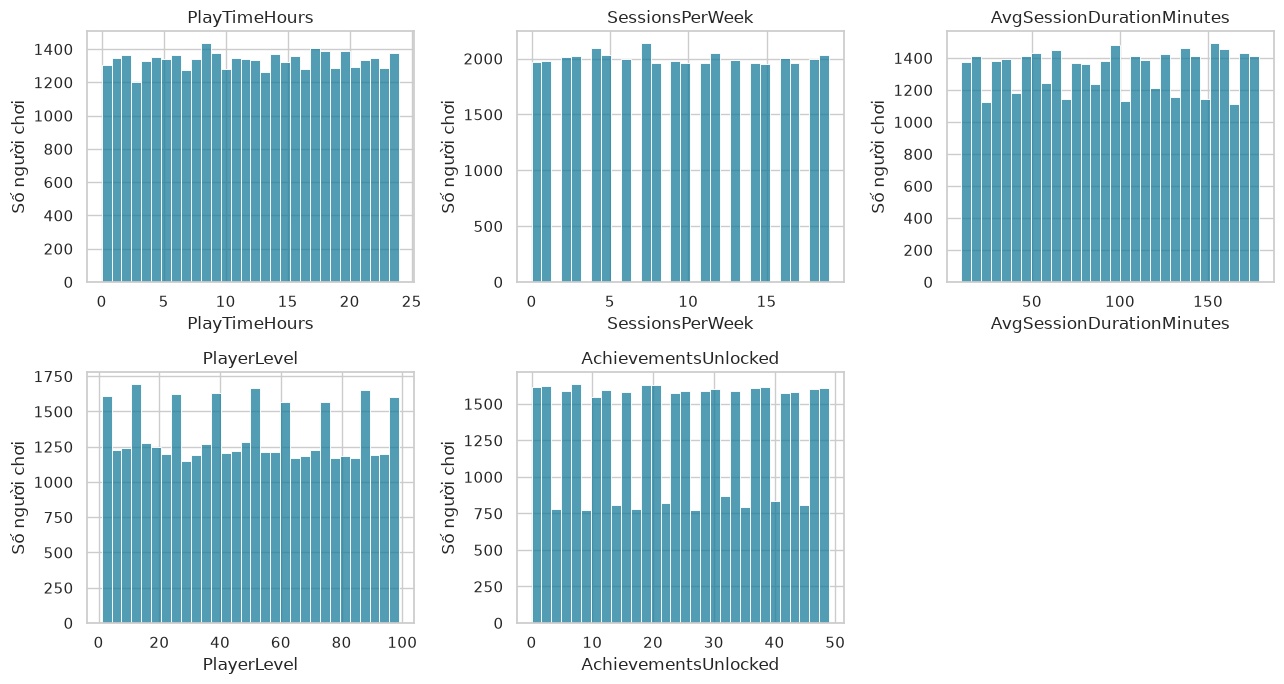

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(df[col], bins=30, color="#197c9b", ax=ax)
    ax.set_title(col); ax.set_ylabel("Số người chơi")
axes.flat[-1].axis("off")
save_plot("02_histograms.png")

Boxplot: đường giữa hộp là trung vị; hộp chứa khoảng 50% dữ liệu ở giữa.
Điểm ngoài râu theo quy tắc IQR là giá trị xa phân phối, cần kiểm tra nghiệp vụ trước khi xử lý.

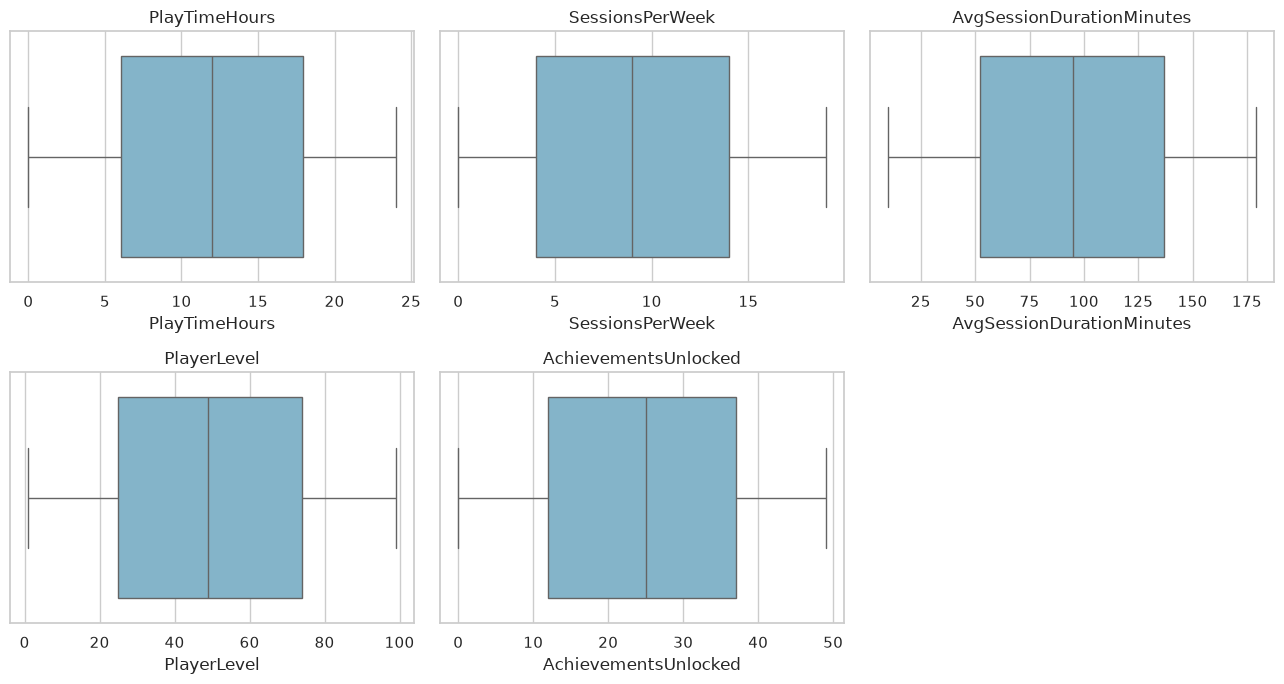

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(x=df[col], ax=ax, color="#79b8d4")
    ax.set_title(col)
axes.flat[-1].axis("off")
save_plot("02_boxplots.png")

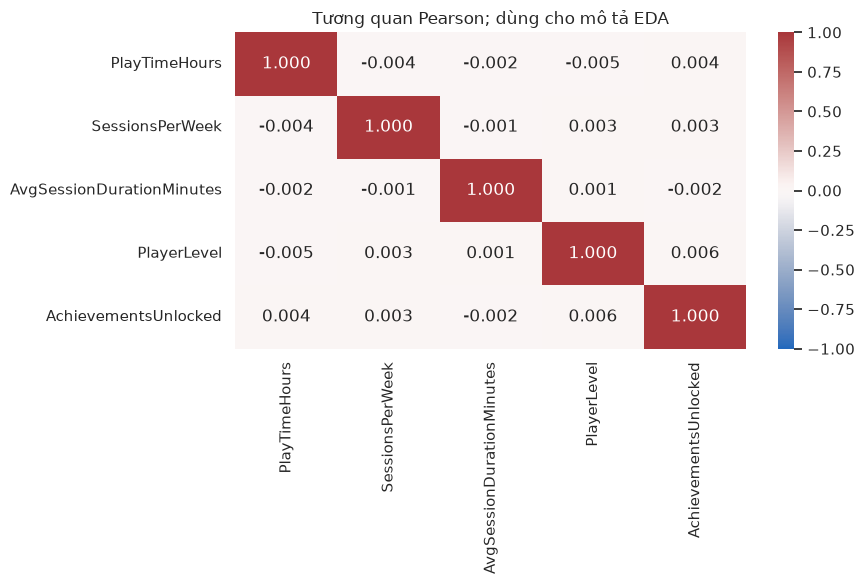

,Kiểm tra,Giá trị
0,"Lệch hai thời lượng quá 0,1 giờ",0.9925
1,Tương quan hai cột,-0.0019


Có **99.25%** dòng không khớp nếu đổi phút sang giờ. Không tự diễn giải PlayTimeHours là giờ/tuần. Sẽ kiểm tra độ nhạy khi bỏ cột này.

In [7]:
plt.figure(figsize=(9, 6))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".3f", cmap="vlag", vmin=-1, vmax=1)
plt.title("Tương quan Pearson; dùng cho mô tả EDA")
save_plot("02_correlations.png")

disagreement = (df.PlayTimeHours - df.AvgSessionDurationMinutes / 60).abs() > 0.1
display(pd.DataFrame({"Kiểm tra": ["Lệch hai thời lượng quá 0,1 giờ", "Tương quan hai cột"],
                      "Giá trị": [disagreement.mean(), df.PlayTimeHours.corr(df.AvgSessionDurationMinutes)]}))
display(Markdown(f"Có **{disagreement.mean():.2%}** dòng không khớp nếu đổi phút sang giờ. "
                 "Không tự diễn giải PlayTimeHours là giờ/tuần. Sẽ kiểm tra độ nhạy khi bỏ cột này."))

## 3. Kiểm tra và làm sạch dữ liệu

Chuỗi trắng, chuỗi không chuyển được thành số, số âm và vô cực phải được kiểm tra trước khi tin vào `isna()`.
Ở đây chỉ chuyển các giá trị không hợp lệ thành thiếu bằng quy tắc xác định;
**chưa tính trung vị trên toàn bộ dữ liệu**. Bộ imputer sẽ được fit sau khi chia train/holdout.

In [8]:
raw = df[FEATURES]
numeric = raw.apply(pd.to_numeric, errors="coerce")
cleaning = pd.DataFrame({
    "missing_raw": raw.isna().sum(),
    "blank_strings": raw.map(lambda v: isinstance(v, str) and v.strip() == "").sum(),
    "invalid_numeric": (numeric.isna() & raw.notna()).sum(),
    "negative": numeric.lt(0).sum(),
    "infinite": pd.Series(np.isinf(numeric).sum(axis=0), index=FEATURES),
})
X = clean_features(df)
cleaning["missing_after_rules"] = X.isna().sum()
display(cleaning)
assert not df.PlayerID.duplicated().any(), "Cần quyết định cách xử lý PlayerID trùng."
assert not df.duplicated().any(), "Cần kiểm tra nguyên nhân trùng dòng."
X.to_csv(NBOUT / "clean_features.csv", index=False, encoding="utf-8-sig")
cleaning.to_csv(NBOUT / "cleaning_audit.csv", encoding="utf-8-sig")
print("Giữ lại", len(X), "người; không xóa dòng tùy tiện.")

,missing_raw,blank_strings,invalid_numeric,negative,infinite,missing_after_rules
PlayTimeHours,0,0,0,0,0,0
SessionsPerWeek,0,0,0,0,0,0
AvgSessionDurationMinutes,0,0,0,0,0,0
PlayerLevel,0,0,0,0,0,0
AchievementsUnlocked,0,0,0,0,0,0


Giữ lại 40034 người; không xóa dòng tùy tiện.


Quy tắc IQR dưới đây chỉ đánh dấu để quan sát, không cắt dữ liệu.
Sau bước làm sạch, mỗi người vẫn giữ nguyên vị trí dòng để truy vết theo `PlayerID`.

In [9]:
q1, q3 = X.quantile(.25), X.quantile(.75)
iqr = q3 - q1
iqr_audit = pd.DataFrame({"q1": q1, "q3": q3,
                          "below_fence": X.lt(q1 - 1.5 * iqr).sum(),
                          "above_fence": X.gt(q3 + 1.5 * iqr).sum()})
display(iqr_audit)
display(X.head())
display(Markdown(f"Sau quy tắc làm sạch có **{int(X.isna().sum().sum())} ô thiếu** "
                 "trong năm đặc trưng. Imputer vẫn được lưu để xử lý đầu vào mới nhất quán."))

,q1,q3,below_fence,above_fence
PlayTimeHours,6.0675,17.9638,0,0
SessionsPerWeek,4.0000,14.0000,0,0
AvgSessionDurationMinutes,52.0000,137.0000,0,0
PlayerLevel,25.0000,74.0000,0,0
AchievementsUnlocked,12.0000,37.0000,0,0


,PlayTimeHours,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked
0,16.2711,6,108,79,25
1,5.5260,5,144,11,10
2,8.2238,16,142,35,41
3,5.2654,9,85,57,47
4,15.5319,2,131,95,37


Sau quy tắc làm sạch có **0 ô thiếu** trong năm đặc trưng. Imputer vẫn được lưu để xử lý đầu vào mới nhất quán.

## 4. Chia dữ liệu và chuẩn hóa

Chia 80% train, 20% holdout với seed 42, không phân tầng bằng nhãn `EngagementLevel`.
Fit `SimpleImputer` và `StandardScaler` chỉ trên train.

$$z_{ij}=\frac{x_{ij}-\mu_{j,train}}{\sigma_{j,train}}$$

Nếu không chuẩn hóa, đơn vị phút và thang cấp độ có thể chi phối khoảng cách.
Năm đầu vào đều là số nên không cần One-Hot. Không đưa ID hoặc nhãn nguồn vào khoảng cách.

In [10]:
X = clean_features(df)
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=.2, random_state=SEED)
assert not set(df.iloc[train_idx].PlayerID) & set(df.iloc[test_idx].PlayerID)
prep = Pipeline([("imputer", SimpleImputer(strategy="median")),
                 ("scaler", StandardScaler())])
Z_train = prep.fit_transform(X.iloc[train_idx])
Z_test = prep.transform(X.iloc[test_idx])
display(pd.DataFrame({"Tập": ["train", "holdout"], "Số người": [len(train_idx), len(test_idx)]}))
display(pd.DataFrame({"mean_train_scaled": Z_train.mean(axis=0),
                      "std_train_scaled": Z_train.std(axis=0)}, index=FEATURES))

,Tập,Số người
0,train,32027
1,holdout,8007


,mean_train_scaled,std_train_scaled
PlayTimeHours,-3.5497e-17,1.0
SessionsPerWeek,-1.1803e-16,1.0
AvgSessionDurationMinutes,-5.5242e-17,1.0
PlayerLevel,9.9836e-17,1.0
AchievementsUnlocked,-5.2802e-17,1.0


,mean_raw_train,std_raw_train,mean_scaled_train,std_scaled_train
PlayTimeHours,12.0144,6.9187,-3.5497e-17,1.0
SessionsPerWeek,9.4792,5.7599,-1.1803e-16,1.0
AvgSessionDurationMinutes,94.8312,48.9694,-5.5242e-17,1.0
PlayerLevel,49.7601,28.6078,9.9836e-17,1.0
AchievementsUnlocked,24.5469,14.4312,-5.2802e-17,1.0


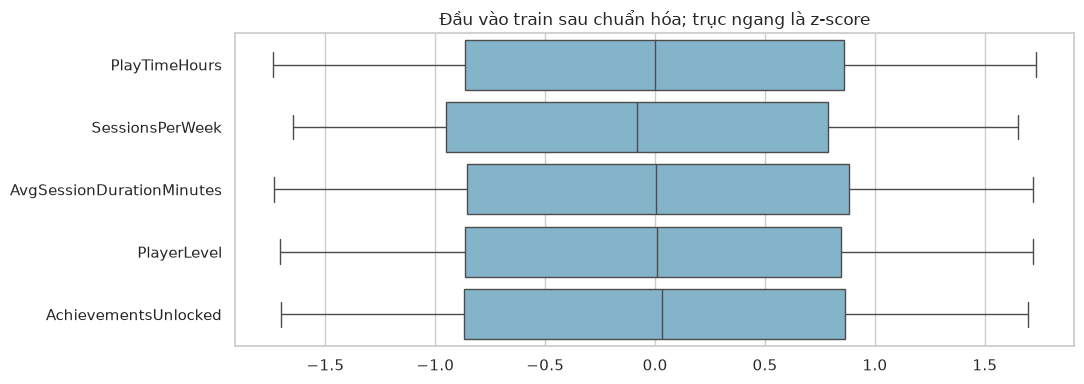

['C:\\Bop\\New folder\\gamer_profiling\\outputs\\notebook\\validation_bd40b6e5a2\\full\\preprocessing.joblib']

In [11]:
before_after = pd.DataFrame({"mean_raw_train": X.iloc[train_idx].mean(),
                             "std_raw_train": X.iloc[train_idx].std(ddof=0),
                             "mean_scaled_train": Z_train.mean(axis=0),
                             "std_scaled_train": Z_train.std(axis=0)})
display(before_after)
plt.figure(figsize=(11, 4))
sns.boxplot(data=pd.DataFrame(Z_train, columns=FEATURES), orient="h", color="#79b8d4")
plt.title("Đầu vào train sau chuẩn hóa; trục ngang là z-score")
save_plot("04_scaled_boxplots.png")
joblib.dump({"prep": prep, "train_idx": train_idx, "test_idx": test_idx,
             "Z_train": Z_train, "Z_test": Z_test}, NBOUT / "preprocessing.joblib")

Trung bình sau chuẩn hóa gần 0 và độ lệch chuẩn gần 1 là kiểm tra trên **train**.
Holdout không bắt buộc có đúng các giá trị đó. Tệp trung gian được lưu riêng trong `outputs/notebook/`;
không ghi đè bộ kết quả dùng cho báo cáo.

## 5. Ward, K-Means và cách kết hợp

Phần này cần chạy notebook 04 trước (hoặc dùng Run All của notebook 00).
Cả ba phương pháp so sánh trên cùng mẫu 4.000 người từ train và cùng các k = 2…8.

**K-Means:** giảm $J=\sum_r\sum_{x\in C_r}\|x-\mu_r\|^2$ bằng cách gán điểm và cập nhật tâm.
**Ward:** gộp hai cụm làm tăng tổng bình phương sai số ít nhất, xây cây rồi cắt ở k.
**Ward + K-Means:** lấy trung bình mỗi cụm Ward làm `init` cho K-Means. Khi đã khóa k,
K-Means mới tinh chỉnh trên toàn train (notebook 06). Ward dùng mẫu vì chi phí bộ nhớ tăng bậc hai.

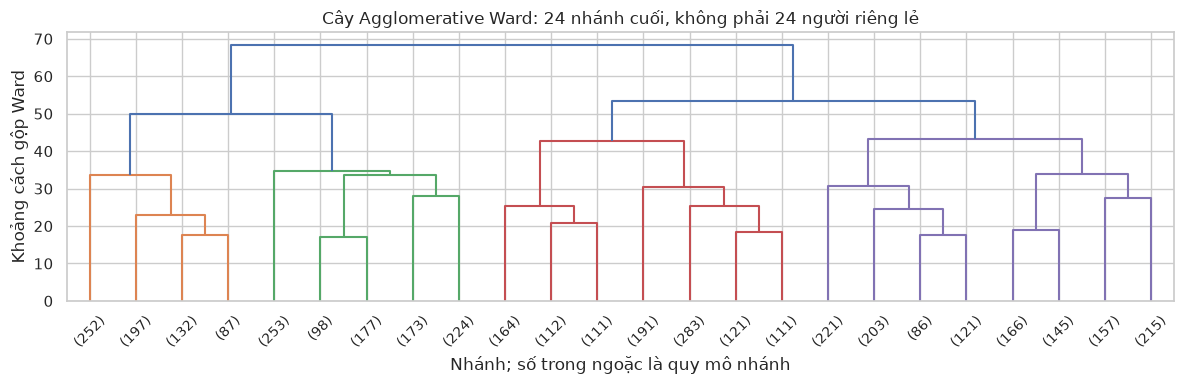

In [12]:
state = joblib.load(require("preprocessing.joblib", "04_data_transformation.ipynb"))
Z_train = state["Z_train"]
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(Z_train), min(4000, len(Z_train)), replace=False)
X_sample = Z_train[sample_idx]
eval_idx = rng.choice(len(X_sample), min(2000, len(X_sample)), replace=False)
distances = pairwise_distances(X_sample[eval_idx])
tree = linkage(X_sample, method="ward", metric="euclidean")
plt.figure(figsize=(12, 4))
dendrogram(tree, truncate_mode="lastp", p=24, show_leaf_counts=True)
plt.title("Cây Agglomerative Ward: 24 nhánh cuối, không phải 24 người riêng lẻ")
plt.xlabel("Nhánh; số trong ngoặc là quy mô nhánh"); plt.ylabel("Khoảng cách gộp Ward")
save_plot("05_dendrogram.png")

Ô dưới là phần kết hợp thực sự: `init=ward_centers`, `n_init=1`.
K-Means thuần dùng k-means++ với 20 khởi tạo. Trong bước chọn k, cả ba cùng học trên mẫu train.
Silhouette dùng một mẫu cố định 2.000 người; DBI dùng cả 4.000 người của mẫu train.

In [13]:
rows, sample_centers = [], {}
for k in range(2, 9):
    ward_labels = cut_tree(tree, n_clusters=k).ravel()
    ward_centers = centers_from_labels(X_sample, ward_labels)
    baseline = KMeans(n_clusters=k, init="k-means++", n_init=20,
                      max_iter=300, random_state=SEED).fit(X_sample)
    hybrid = KMeans(n_clusters=k, init=ward_centers, n_init=1,
                    max_iter=300, random_state=SEED).fit(X_sample)
    candidates = {"KMeans": (baseline.labels_, baseline.cluster_centers_),
                  "Ward": (ward_labels, ward_centers),
                  "Ward_KMeans": (hybrid.labels_, hybrid.cluster_centers_)}
    for name, (labels, centers) in candidates.items():
        sample_centers[(name, k)] = centers
        rows.append({"method": name, "k": k,
                     **metrics(X_sample, labels, eval_idx, distances)})
search = pd.DataFrame(rows)
display(search)

,method,k,silhouette,davies_bouldin,min_cluster_pct
0,KMeans,2,0.1477,2.3018,49.725
1,Ward,2,0.1155,2.6192,39.825
2,Ward_KMeans,2,0.1512,2.3196,50.000
3,KMeans,3,0.1360,1.9657,31.025
4,Ward,3,0.0909,2.4143,27.325
5,Ward_KMeans,3,0.1386,1.9821,31.800
6,KMeans,4,0.1469,1.8449,24.025
7,Ward,4,0.0857,2.2524,16.700
8,Ward_KMeans,4,0.1415,1.8612,24.550
9,KMeans,5,0.1497,1.6162,18.500


,method,k,silhouette,davies_bouldin,min_cluster_pct,rank_silhouette,rank_dbi,rank_sum
18,KMeans,8,0.1574,1.4336,11.275,1.0,1.0,2.0
12,KMeans,6,0.1547,1.4967,16.325,3.0,2.0,5.0
15,KMeans,7,0.1563,1.5236,12.150,2.0,3.0,5.0
9,KMeans,5,0.1497,1.6162,18.500,4.0,4.0,8.0
6,KMeans,4,0.1469,1.8449,24.025,6.0,5.0,11.0
0,KMeans,2,0.1477,2.3018,49.725,5.0,7.0,12.0
3,KMeans,3,0.1360,1.9657,31.025,7.0,6.0,13.0
13,Ward,6,0.0860,1.9838,9.675,3.0,3.0,6.0
1,Ward,2,0.1155,2.6192,39.825,1.0,7.0,8.0
4,Ward,3,0.0909,2.4143,27.325,2.0,6.0,8.0


,method,selected_k
0,KMeans,8
1,Ward,6
2,Ward_KMeans,8


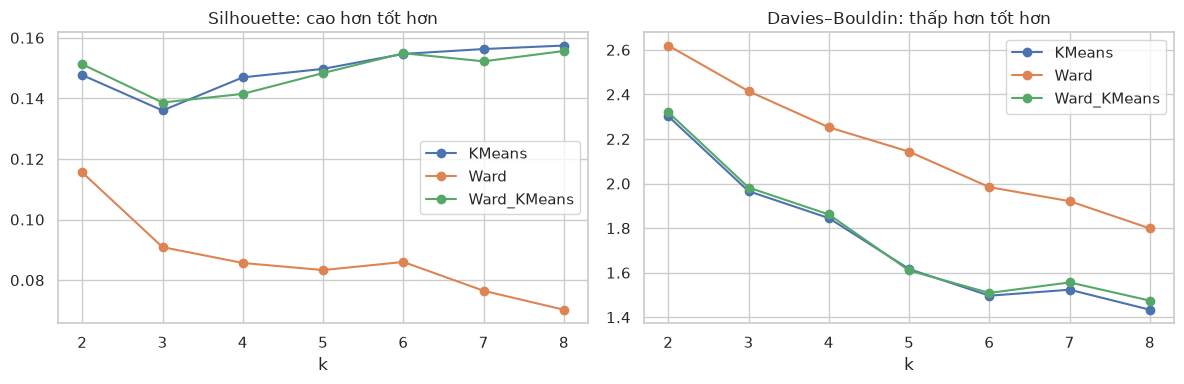

['C:\\Bop\\New folder\\gamer_profiling\\outputs\\notebook\\validation_bd40b6e5a2\\full\\selection.joblib']

In [14]:
ranked = search.copy()
ranked["rank_silhouette"] = ranked.groupby("method").silhouette.rank(ascending=False, method="min")
ranked["rank_dbi"] = ranked.groupby("method").davies_bouldin.rank(method="min")
ranked["rank_sum"] = ranked.rank_silhouette + ranked.rank_dbi
selected = {name: choose_k(search[search.method == name]) for name in METHODS}
display(ranked.sort_values(["method", "rank_sum", "k"]))
display(pd.DataFrame({"method": list(selected), "selected_k": list(selected.values())}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, group in search.groupby("method"):
    axes[0].plot(group.k, group.silhouette, "o-", label=name)
    axes[1].plot(group.k, group.davies_bouldin, "o-", label=name)
axes[0].set_title("Silhouette: cao hơn tốt hơn")
axes[1].set_title("Davies–Bouldin: thấp hơn tốt hơn")
for ax in axes:
    ax.set_xlabel("k"); ax.legend()
save_plot("05_selection.png")
search.to_csv(NBOUT / "model_selection.csv", index=False)
joblib.dump({"selected": selected, "centers": sample_centers, "sample_idx": sample_idx,
             "eval_idx": eval_idx, "tree": tree, "search": search}, NBOUT / "selection.joblib")

Quy tắc chọn: tổng hạng Silhouette giảm và DBI tăng nhỏ nhất; hòa thì ưu tiên Silhouette, rồi k nhỏ.
**k = 8 ở biên trên dải đã thử**: đây là lựa chọn trong dải 2–8, chưa chứng minh tám nhóm tự nhiên.
Phương pháp kết hợp là sản phẩm chính theo đề, được xác định trước khi xem holdout.

## 6. Đánh giá holdout và độ nhạy

Cần tệp từ notebook 04 và 05. Khóa k trước khi chấm holdout, không chọn lại theo holdout.

$$s(i)=\frac{b(i)-a(i)}{\max(a(i),b(i))}$$

$a(i)$ là khoảng cách trung bình tới điểm khác cùng cụm; $b(i)$ là khoảng cách trung bình nhỏ nhất
tới một cụm khác. Ví dụ a=2, b=5 cho s=0,6. Gần 0 nghĩa là ranh giới chồng lấn.

$$DBI=\frac{1}{k}\sum_r\max_{s\ne r}\frac{S_r+S_s}{\|\mu_r-\mu_s\|}$$

$S_r$ là khoảng cách Euclidean trung bình tới tâm cụm r. DBI thấp hơn tốt hơn.
Hai chỉ số đo hình học, chưa đo tác động doanh thu. Không có nhãn cụm chuẩn để tính Accuracy.

In [15]:
state = joblib.load(require("preprocessing.joblib", "04_data_transformation.ipynb"))
selection = joblib.load(require("selection.joblib", "05_clustering.ipynb"))
Z_train, Z_test = state["Z_train"], state["Z_test"]
selected = selection["selected"]
# Phát lại thứ tự rút mẫu của pipeline gốc để dùng đúng mẫu Silhouette holdout.
rng = np.random.default_rng(SEED)
rng.choice(len(Z_train), len(selection["sample_idx"]), replace=False)
rng.choice(len(selection["sample_idx"]), len(selection["eval_idx"]), replace=False)
test_eval = rng.choice(len(Z_test), min(2000, len(Z_test)), replace=False)
test_distances = pairwise_distances(Z_test[test_eval])
evaluations, fitted = [], {}
for name in METHODS:
    k = selected[name]
    if name == "Ward":
        model = None
        centers = selection["centers"][(name, k)]
        labels = pairwise_distances_argmin(Z_test, centers)
        evaluation_type = "holdout_centroid_extension"
    else:
        init = "k-means++" if name == "KMeans" else selection["centers"][("Ward", k)]
        model = KMeans(n_clusters=k, init=init, n_init=20 if name == "KMeans" else 1,
                       max_iter=300, random_state=SEED).fit(Z_train)
        centers = model.cluster_centers_
        labels = model.predict(Z_test)
        evaluation_type = "holdout_predict"
    fitted[name] = {"model": model, "centers": centers}
    evaluations.append({"method": name, "k": k, "evaluation": evaluation_type,
                        **metrics(Z_test, labels, test_eval, test_distances)})
evaluation = pd.DataFrame(evaluations)
display(evaluation)
evaluation.to_csv(NBOUT / "holdout_metrics.csv", index=False)
model = fitted["Ward_KMeans"]["model"]
reference_labels = model.predict(Z_test)

,method,k,evaluation,silhouette,davies_bouldin,min_cluster_pct
0,KMeans,8,holdout_predict,0.1501,1.4461,11.1153
1,Ward,6,holdout_centroid_extension,0.1435,1.6267,13.9753
2,Ward_KMeans,8,holdout_predict,0.1540,1.4322,11.6648


**Lưu ý Ward thuần:** không có `predict` tự nhiên. Bảng dùng tâm các cụm Ward để gán holdout,
không phải Ward chính xác trên toàn holdout. K-Means thuần và mô hình kết hợp được fit trên toàn train.
Biểu đồ Silhouette dưới đây dùng đúng mẫu holdout được chấm ở bảng trên.

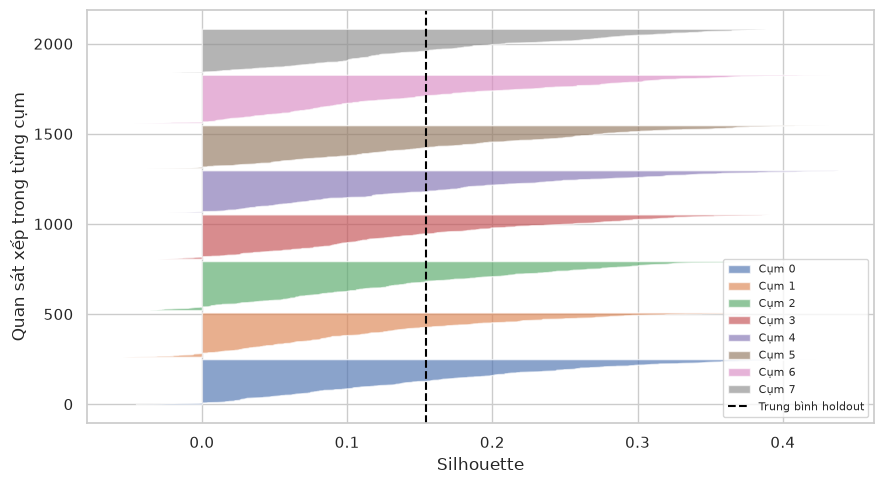

In [16]:
values = silhouette_samples(Z_test[test_eval], reference_labels[test_eval])
plt.figure(figsize=(9, 5))
start = 0
for cluster in sorted(np.unique(reference_labels)):
    within = np.sort(values[reference_labels[test_eval] == cluster])
    end = start + len(within)
    plt.fill_betweenx(np.arange(start, end), 0, within, alpha=.65, label=f"Cụm {cluster}")
    start = end + 12
plt.axvline(values.mean(), color="black", linestyle="--", label="Trung bình holdout")
plt.xlabel("Silhouette"); plt.ylabel("Quan sát xếp trong từng cụm"); plt.legend(fontsize=8)
save_plot("06_holdout_silhouette.png")

Đổi seed lấy mẫu Ward nhưng giữ nguyên train, holdout và k. ARI so sánh hai phân hoạch, có điều chỉnh
ngẫu nhiên và không phụ thuộc số hiệu nhãn. **ARI ở đây đo ổn định, không đo đúng sai với nhãn thật.**

In [17]:
k = selected["Ward_KMeans"]
stability_rows = []
for seed in [7, 21, 84, 123, 2026]:
    si = np.random.default_rng(seed).choice(len(Z_train), len(selection["sample_idx"]), replace=False)
    zz = Z_train[si]
    stree = linkage(zz, method="ward")
    wl = cut_tree(stree, n_clusters=k).ravel()
    trial = KMeans(n_clusters=k, init=centers_from_labels(zz, wl), n_init=1,
                   max_iter=300, random_state=seed).fit(Z_train)
    labels = trial.predict(Z_test)
    stability_rows.append({"seed": seed, "ari_vs_seed42": adjusted_rand_score(reference_labels, labels),
                           **metrics(Z_test, labels, test_eval, test_distances)})
stability = pd.DataFrame(stability_rows)
display(stability)
display(Markdown(f"ARI trung bình **{stability.ari_vs_seed42.mean():.4f}**, "
                 f"thấp nhất **{stability.ari_vs_seed42.min():.4f}**. "
                 "Phân hoạch còn nhạy với mẫu khởi tạo; chưa nên dùng nhãn như quy tắc vận hành cố định."))
stability.to_csv(NBOUT / "stability.csv", index=False)

,seed,ari_vs_seed42,silhouette,davies_bouldin,min_cluster_pct
0,7,0.2814,0.1571,1.4636,11.6273
1,21,0.2612,0.1547,1.4534,10.7781
2,84,0.2755,0.1591,1.4281,11.6648
3,123,0.3958,0.1510,1.4663,11.4025
4,2026,0.3523,0.1596,1.4263,10.7656


ARI trung bình **0.3132**, thấp nhất **0.2612**. Phân hoạch còn nhạy với mẫu khởi tạo; chưa nên dùng nhãn như quy tắc vận hành cố định.

In [18]:
keep = [i for i, feature in enumerate(FEATURES) if feature != "PlayTimeHours"]
alt_sample = Z_train[selection["sample_idx"]][:, keep]
alt_tree = linkage(alt_sample, method="ward")
alt_ward = cut_tree(alt_tree, n_clusters=k).ravel()
alt = KMeans(n_clusters=k, init=centers_from_labels(alt_sample, alt_ward), n_init=1,
             max_iter=300, random_state=SEED).fit(Z_train[:, keep])
alt_labels = alt.predict(Z_test[:, keep])
sensitivity = {"excluded": "PlayTimeHours", "k_fixed": k,
               "ari_vs_main": adjusted_rand_score(reference_labels, alt_labels),
               **metrics(Z_test[:, keep], alt_labels, test_eval,
                         pairwise_distances(Z_test[test_eval][:, keep]))}
display(pd.DataFrame([sensitivity]))
(NBOUT / "feature_sensitivity.json").write_text(json.dumps(sensitivity, indent=2), encoding="utf-8")
joblib.dump({"prep": state["prep"], "model": model, "features": FEATURES,
             "method": "Ward_KMeans", "seed": SEED}, NBOUT / "player_model.joblib")

,excluded,k_fixed,ari_vs_main,silhouette,davies_bouldin,min_cluster_pct
0,PlayTimeHours,8,0.2458,0.225,1.1132,11.6898


['C:\\Bop\\New folder\\gamer_profiling\\outputs\\notebook\\validation_bd40b6e5a2\\full\\player_model.joblib']

Bỏ PlayTimeHours làm thay đổi không gian từ năm xuống bốn chiều. ARI cho biết gán nhóm thay đổi ra sao;
không dùng Silhouette/DBI ở hai không gian khác nhau để xếp hạng thắng thua trực tiếp.
Silhouette khoảng 0,15 và ARI trung bình khoảng 0,31 cho thấy ranh giới chưa rõ và còn nhạy với mẫu.

## 7. Hồ sơ người chơi và trực quan hóa

Cần mô hình từ notebook 06. Dùng mô hình fit train để gán toàn bộ dữ liệu và mô tả hồ sơ.
Các bảng toàn bộ dân số này không phải đánh giá ngoài mẫu. Tên cụm là mô tả tương đối,
số hiệu cụm không phải thứ hạng; nhóm không được tự động gọi là High-Spenders.

In [19]:
artifact = joblib.load(require("player_model.joblib", "06_model_evaluation.ipynb"))
X = clean_features(df)
Z_all = artifact["prep"].transform(X)
labels = artifact["model"].predict(Z_all)
players = df.assign(cluster=labels)
profile = players.groupby("cluster")[FEATURES].mean()
profile["count"] = players.groupby("cluster").size()
profile["share_pct"] = profile["count"] / len(players) * 100
profile["purchase_rate"] = players.groupby("cluster").InGamePurchases.mean()
freq = profile.SessionsPerWeek.rank(pct=True)
duration = profile.AvgSessionDurationMinutes.rank(pct=True)
profile["profile"] = [
    ("Chơi thường xuyên" if freq[c] > .5 else "Chơi ít phiên") + ", " +
    ("phiên dài" if duration[c] > .5 else "phiên ngắn") for c in profile.index]
display(profile)
assert profile["count"].sum() == len(df)
profile.to_csv(NBOUT / "cluster_profiles.csv", encoding="utf-8-sig")
players.to_csv(NBOUT / "player_assignments.csv", index=False, encoding="utf-8-sig")
artifact["cluster_names"] = profile["profile"].to_dict()
joblib.dump(artifact, NBOUT / "player_model.joblib")

,PlayTimeHours,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,count,share_pct,purchase_rate,profile
cluster,,,,,,,,,
0,6.5497,6.6017,62.8103,68.9703,35.6209,5315,13.2762,0.2036,"Chơi ít phiên, phiên ngắn"
1,7.0248,12.8650,132.4144,27.5363,33.4307,4964,12.3995,0.2025,"Chơi thường xuyên, phiên dài"
2,17.1040,5.8185,133.4981,29.6941,16.5355,5354,13.3736,0.1892,"Chơi ít phiên, phiên dài"
3,17.2749,11.3410,59.0600,71.1918,12.9503,5015,12.5269,0.1936,"Chơi thường xuyên, phiên ngắn"
4,17.0324,10.8286,130.6931,73.8669,36.1437,4838,12.0847,0.2013,"Chơi thường xuyên, phiên dài"
5,6.4777,9.3634,131.1950,71.7028,12.3751,4775,11.9274,0.2080,"Chơi ít phiên, phiên dài"
6,6.9532,9.6208,54.9924,26.2755,12.8818,4839,12.0872,0.2085,"Chơi ít phiên, phiên ngắn"
7,17.5337,9.8423,54.3127,28.7270,35.8435,4934,12.3245,0.2015,"Chơi thường xuyên, phiên ngắn"


['C:\\Bop\\New folder\\gamer_profiling\\outputs\\notebook\\validation_bd40b6e5a2\\full\\player_model.joblib']

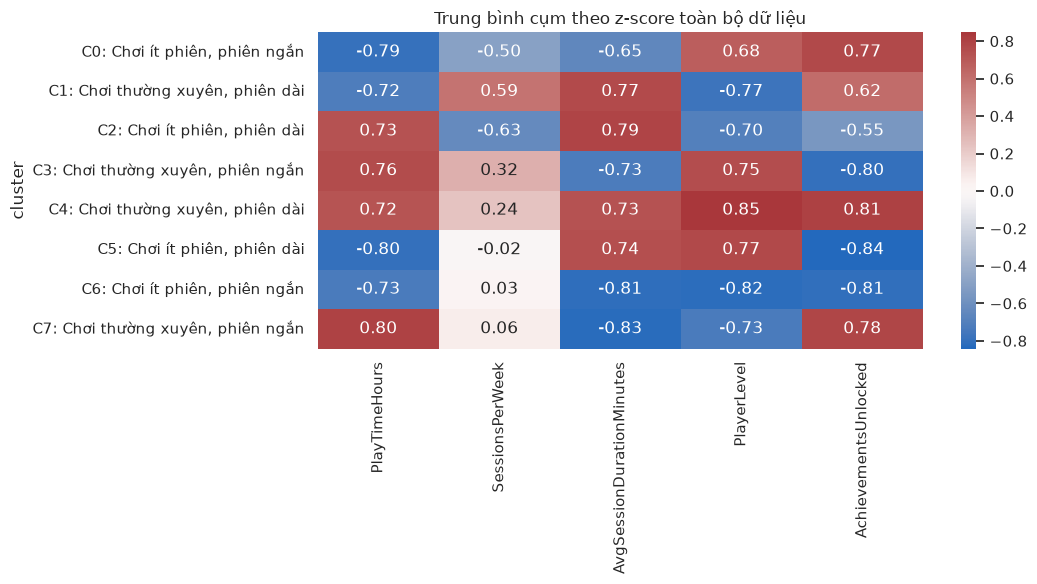

In [20]:
normalized = (profile[FEATURES] - X.mean()) / X.std(ddof=0)
plt.figure(figsize=(11, 6))
sns.heatmap(normalized, annot=True, fmt=".2f", cmap="vlag", center=0,
            yticklabels=[f"C{c}: {profile.loc[c, 'profile']}" for c in profile.index])
plt.title("Trung bình cụm theo z-score toàn bộ dữ liệu")
save_plot("07_profiles.png")

Màu nóng: cao hơn trung bình chung; màu lạnh: thấp hơn. Các cụm có thể trùng tên mô tả,
vì tên chỉ tóm tắt tần suất × thời lượng, còn mô hình học năm biến. Dùng ID cụm để phân biệt.
PCA chỉ là hình chiếu sau học, không phải đầu vào của phân cụm.

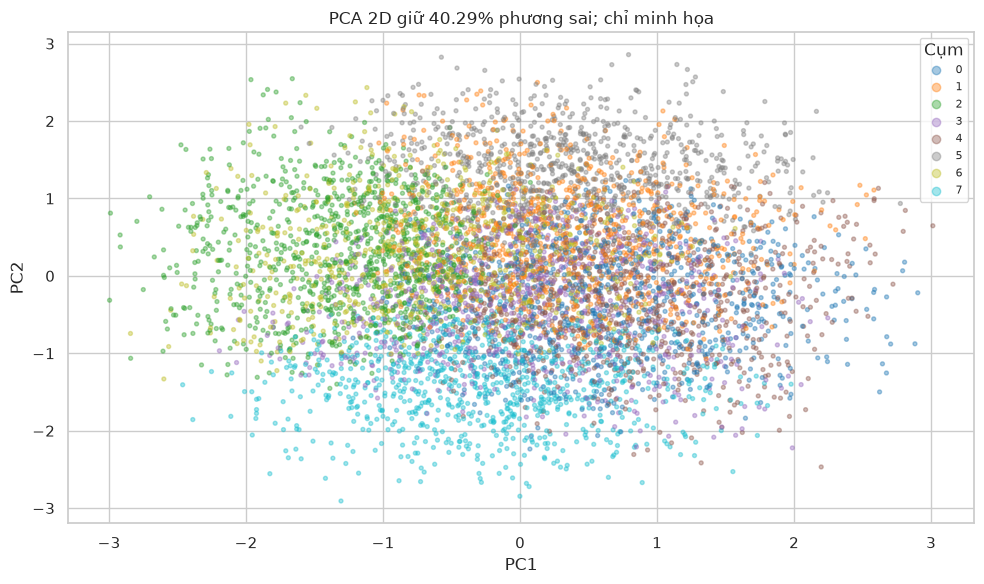

In [21]:
pca = PCA(n_components=2).fit(Z_all)
xy = pca.transform(Z_all)
take = np.random.default_rng(SEED).choice(len(df), min(7000, len(df)), replace=False)
plt.figure(figsize=(10, 6))
scatter = plt.scatter(xy[take, 0], xy[take, 1], c=labels[take], cmap="tab10", s=8, alpha=.4)
plt.legend(*scatter.legend_elements(), title="Cụm", fontsize=8)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title(f"PCA 2D giữ {pca.explained_variance_ratio_.sum():.2%} phương sai; chỉ minh họa")
save_plot("07_pca.png")

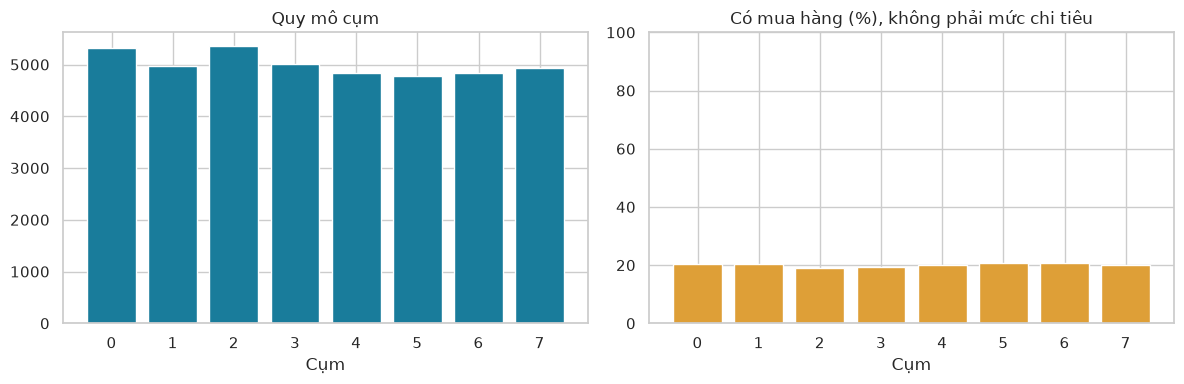

EngagementLevel,High,Low,Medium
cluster,,,
0,0.0534,0.3910,0.5556
1,0.5977,0.0570,0.3453
2,0.2079,0.3214,0.4707
3,0.1470,0.2921,0.5609
4,0.5205,0.0746,0.4049
5,0.3941,0.1516,0.4542
6,0.0833,0.4042,0.5125
7,0.0876,0.3518,0.5606


EngagementLevel chỉ được đối chiếu **sau học**. Tỷ lệ có mua không chứng minh nhóm chi tiêu cao hoặc sẽ phản ứng tốt hơn với ưu đãi.

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(profile.index, profile["count"], color="#197c9b")
axes[0].set_title("Quy mô cụm"); axes[0].set_xlabel("Cụm")
axes[1].bar(profile.index, profile.purchase_rate * 100, color="#de9f37")
axes[1].set_ylim(0, 100); axes[1].set_title("Có mua hàng (%), không phải mức chi tiêu")
axes[1].set_xlabel("Cụm")
save_plot("07_sizes_purchases.png")
engagement = pd.crosstab(players.cluster, players.EngagementLevel, normalize="index")
display(engagement)
display(Markdown("EngagementLevel chỉ được đối chiếu **sau học**. "
                 "Tỷ lệ có mua không chứng minh nhóm chi tiêu cao hoặc sẽ phản ứng tốt hơn với ưu đãi."))

## 8. Gán người chơi và đề xuất chiến lược

Cần notebook 07 để có mô hình và tên hồ sơ. Với dữ liệu mới chỉ `transform` rồi `predict`;
không fit lại scaler trên người mới. Ví dụ dưới lấy năm dòng thật của tập holdout,
không tạo hồ sơ giả để đưa vào kết quả.

In [23]:
artifact = joblib.load(require("player_model.joblib", "07_player_profiling.ipynb"))
state = joblib.load(require("preprocessing.joblib", "04_data_transformation.ipynb"))
examples = df.iloc[state["test_idx"][:5]][["PlayerID"] + FEATURES].copy()
examples["cluster"] = artifact["model"].predict(artifact["prep"].transform(clean_features(examples)))
examples["profile"] = examples.cluster.map(artifact["cluster_names"])
display(examples)
examples.to_csv(NBOUT / "prediction_examples.csv", index=False, encoding="utf-8-sig")

,PlayerID,PlayTimeHours,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,cluster,profile
34667,43667,3.3269,16,63,43,6,6,"Chơi ít phiên, phiên ngắn"
22227,31227,19.6265,10,99,48,11,3,"Chơi thường xuyên, phiên ngắn"
24899,33899,23.3221,11,17,12,34,7,"Chơi thường xuyên, phiên ngắn"
35415,44415,10.3488,7,149,44,38,1,"Chơi thường xuyên, phiên dài"
21440,30440,6.2387,10,127,14,4,6,"Chơi ít phiên, phiên ngắn"


**Chiến lược là giả thuyết:** không có tiền mua, chi phí hoặc can thiệp nên chưa tính ROI/uplift.
Có thể thử trang trí nhỏ cho phiên ngắn, nội dung mở rộng cho phiên dài, điểm chạm khi quay lại
cho nhóm ít phiên. Không suy ra mức sẵn sàng chi trả từ cấp độ hoặc thành tích.

In [24]:
profile = pd.read_csv(require("cluster_profiles.csv", "07_player_profiling.ipynb"))
strategies = []
for row in profile.itertuples():
    short = "phiên ngắn" in row.profile
    frequent = "thường xuyên" in row.profile
    strategies.append({"Cụm": row.cluster, "Hồ sơ": row.profile,
                       "Giả thuyết nội dung": "Gói trang trí nhỏ, dễ trải nghiệm" if short else "Nội dung mở rộng, trang trí theo chủ đề",
                       "Điểm chạm": "Kết thúc phiên; giới hạn nhắc mua" if frequent else "Khi quay lại game; nhiệm vụ ngắn",
                       "Kiểm chứng": "A/B test: conversion, doanh thu/người, retention, hoàn tiền"})
strategy = pd.DataFrame(strategies)
display(strategy)
strategy.to_csv(NBOUT / "strategies.csv", index=False, encoding="utf-8-sig")

,Cụm,Hồ sơ,Giả thuyết nội dung,Điểm chạm,Kiểm chứng
0,0,"Chơi ít phiên, phiên ngắn","Gói trang trí nhỏ, dễ trải nghiệm",Khi quay lại game; nhiệm vụ ngắn,"A/B test: conversion, doanh thu/người, retenti..."
1,1,"Chơi thường xuyên, phiên dài","Nội dung mở rộng, trang trí theo chủ đề",Kết thúc phiên; giới hạn nhắc mua,"A/B test: conversion, doanh thu/người, retenti..."
2,2,"Chơi ít phiên, phiên dài","Nội dung mở rộng, trang trí theo chủ đề",Khi quay lại game; nhiệm vụ ngắn,"A/B test: conversion, doanh thu/người, retenti..."
3,3,"Chơi thường xuyên, phiên ngắn","Gói trang trí nhỏ, dễ trải nghiệm",Kết thúc phiên; giới hạn nhắc mua,"A/B test: conversion, doanh thu/người, retenti..."
4,4,"Chơi thường xuyên, phiên dài","Nội dung mở rộng, trang trí theo chủ đề",Kết thúc phiên; giới hạn nhắc mua,"A/B test: conversion, doanh thu/người, retenti..."
5,5,"Chơi ít phiên, phiên dài","Nội dung mở rộng, trang trí theo chủ đề",Khi quay lại game; nhiệm vụ ngắn,"A/B test: conversion, doanh thu/người, retenti..."
6,6,"Chơi ít phiên, phiên ngắn","Gói trang trí nhỏ, dễ trải nghiệm",Khi quay lại game; nhiệm vụ ngắn,"A/B test: conversion, doanh thu/người, retenti..."
7,7,"Chơi thường xuyên, phiên ngắn","Gói trang trí nhỏ, dễ trải nghiệm",Kết thúc phiên; giới hạn nhắc mua,"A/B test: conversion, doanh thu/người, retenti..."


Phân ngẫu nhiên control/treatment **trong từng cụm**, khóa nhãn trước thử nghiệm, đo trên tất cả
người đủ điều kiện được phân nhánh. Cần bổ sung giao dịch có số tiền/thời điểm, wins/losses,
vật phẩm theo thời gian và MMR/Elo trước khi mở rộng diễn giải.

Cuối cùng kiểm chứng notebook với bộ kết quả đã dùng trong báo cáo. Hai cách chạy phải khớp
bảng chọn k, điểm holdout, hồ sơ, độ ổn định và gán người mới trong sai số số học cho phép.

In [25]:
numerical_columns = ["silhouette", "davies_bouldin", "min_cluster_pct"]
checks = []
for filename, keys, values in [
    ("model_selection.csv", ["method", "k"], numerical_columns),
    ("holdout_metrics.csv", ["method", "k"], numerical_columns),
    ("stability.csv", ["seed"], ["ari_vs_seed42"] + numerical_columns),
    ("cluster_profiles.csv", ["cluster"], FEATURES + ["count", "share_pct", "purchase_rate"]),
]:
    new = pd.read_csv(require(filename, "04 → 07")).sort_values(keys).reset_index(drop=True)
    old = pd.read_csv(ROOT / "outputs" / filename).sort_values(keys).reset_index(drop=True)
    pd.testing.assert_frame_equal(new[keys], old[keys], check_dtype=False)
    np.testing.assert_allclose(new[values].to_numpy(float), old[values].to_numpy(float), rtol=1e-7, atol=1e-9)
    checks.append({"Kiểm tra": filename, "Kết quả": "Khớp kết quả báo cáo"})
original_examples = pd.read_csv(ROOT / "outputs/prediction_examples.csv")
np.testing.assert_array_equal(examples.cluster, original_examples.cluster)
all_predictions = artifact["model"].predict(artifact["prep"].transform(clean_features(df)))
original_labels = pd.read_csv(ROOT / "outputs/player_assignments.csv").cluster.to_numpy()
assert adjusted_rand_score(all_predictions, original_labels) == 1.0
checks.append({"Kiểm tra": "Gán nhóm toàn bộ 40.034 người và ví dụ mới", "Kết quả": "Khớp mô hình đã nộp"})
sensitivity = json.loads((NBOUT / "feature_sensitivity.json").read_text(encoding="utf-8"))
for key in ["ari_vs_main", "silhouette", "davies_bouldin"]:
    np.testing.assert_allclose(sensitivity[key], reference["feature_sensitivity"][key], rtol=1e-7, atol=1e-9)
checks.append({"Kiểm tra": "Bỏ PlayTimeHours", "Kết quả": "Khớp phân tích độ nhạy"})
display(pd.DataFrame(checks))
final = pd.read_csv(NBOUT / "holdout_metrics.csv").set_index("method").loc["Ward_KMeans"]
display(Markdown(f"**Kết quả chạy:** k = {int(final.k)} trong dải 2–8; "
                 f"Silhouette holdout = **{final.silhouette:.4f}**; DBI = **{final.davies_bouldin:.4f}**. "
                 "Ranh giới còn chồng lấn; dữ liệu tổng hợp và độ nhạy mẫu giới hạn khả năng áp dụng."))
(NBOUT / "verification.json").write_text(json.dumps({"passed": True, "checks": checks},
                                                    ensure_ascii=False, indent=2), encoding="utf-8")

,Kiểm tra,Kết quả
0,model_selection.csv,Khớp kết quả báo cáo
1,holdout_metrics.csv,Khớp kết quả báo cáo
2,stability.csv,Khớp kết quả báo cáo
3,cluster_profiles.csv,Khớp kết quả báo cáo
4,Gán nhóm toàn bộ 40.034 người và ví dụ mới,Khớp mô hình đã nộp
5,Bỏ PlayTimeHours,Khớp phân tích độ nhạy


**Kết quả chạy:** k = 8 trong dải 2–8; Silhouette holdout = **0.1540**; DBI = **1.4322**. Ranh giới còn chồng lấn; dữ liệu tổng hợp và độ nhạy mẫu giới hạn khả năng áp dụng.

618